In [1]:
import time
import random
import statistics
import matplotlib.pyplot as plt

In [2]:
# List indexing
def list_indexing(arr):
    return arr[len(arr) // 2]


# Linear search
def linear_search(arr, target):
    for i in range(len(arr)):
        if arr[i] == target:
            return i
    return -1


# Binary search
def binary_search(arr, target):
    low = 0
    high = len(arr) - 1

    while low <= high:
        mid = (low + high) // 2

        if arr[mid] == target:
            return mid
        elif arr[mid] < target:
            low = mid + 1
        else:
            high = mid - 1

    return -1


# Merge sort
def merge_sort(arr):
    if len(arr) <= 1:
        return arr

    mid = len(arr) // 2
    left = merge_sort(arr[:mid])
    right = merge_sort(arr[mid:])

    result = []
    i = 0
    j = 0

    while i < len(left) and j < len(right):
        if left[i] < right[j]:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1

    result.extend(left[i:])
    result.extend(right[j:])

    return result


# Double-loop pair counter
def pair_counter(arr):
    count = 0

    for i in range(len(arr)):
        for j in range(i + 1, len(arr)):
            count += 1

    return count


# Exponential subset enumeration
def subset_enumeration(arr):
    count = 0

    for i in range(2 ** len(arr)):
        count += 1

    return count

In [3]:
# Function to measure execution time using repeated trials
def measure_time(function, data, trials=5):
    times = []

    for i in range(trials):
        start = time.perf_counter()
        function(data)
        end = time.perf_counter()

        times.append(end - start)
    return statistics.median(times)

In [4]:
# Input sizes for different algorithms
sizes = [100, 500, 1000, 2000, 4000]

index_times = []
linear_times = []
binary_times = []
merge_times = []
pair_times = []

# Measure algorithms for increasing input sizes
for n in sizes:
    data = list(range(n))
    target = n - 1

    index_times.append(measure_time(list_indexing, data))
    linear_times.append(measure_time(lambda arr: linear_search(arr, target), data))
    binary_times.append(measure_time(lambda arr: binary_search(arr, target), data))
    merge_times.append(measure_time(merge_sort, data))
    pair_times.append(measure_time(pair_counter, data))

print("Benchmarking completed.")

Benchmarking completed.


In [5]:
# Small input sizes for exponential subset enumeration
exp_sizes = [5, 10, 15, 18, 20]
exp_times = []

for n in exp_sizes:
    data = list(range(n))
    t = measure_time(subset_enumeration, data)
    exp_times.append(t)

print("Exponential benchmarking completed.")

Exponential benchmarking completed.


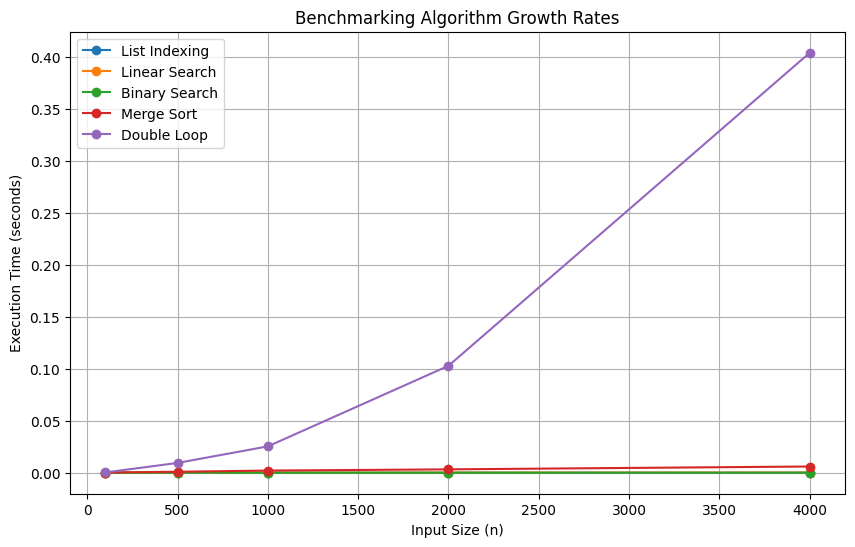

In [6]:
# Plot execution times of different algorithms
plt.figure(figsize=(10, 6))

plt.plot(sizes, index_times, marker='o', label='List Indexing')
plt.plot(sizes, linear_times, marker='o', label='Linear Search')
plt.plot(sizes, binary_times, marker='o', label='Binary Search')
plt.plot(sizes, merge_times, marker='o', label='Merge Sort')
plt.plot(sizes, pair_times, marker='o', label='Double Loop')

plt.xlabel("Input Size (n)")
plt.ylabel("Execution Time (seconds)")
plt.title("Benchmarking Algorithm Growth Rates")
plt.legend()
plt.grid(True)

plt.show()

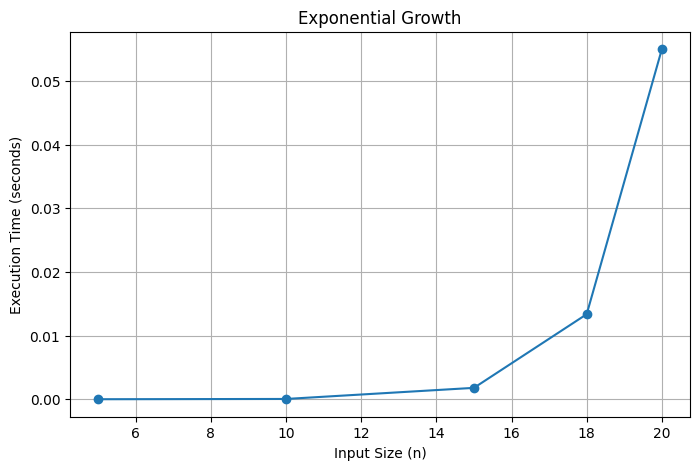

In [7]:
# Plot execution time of exponential subset enumeration
plt.figure(figsize=(8, 5))

plt.plot(exp_sizes, exp_times, marker='o')

plt.xlabel("Input Size (n)")
plt.ylabel("Execution Time (seconds)")
plt.title("Exponential Growth")
plt.grid(True)

plt.show()

In [8]:
# Display theoretical and experimental comparison
print("Algorithm          Theoretical Complexity")
print("--------------------------------------")
print("List Indexing     O(1)")
print("Binary Search     O(log n)")
print("Linear Search    O(n)")
print("Merge Sort      O(n log n)")
print("Double Loop     O(n^2)")
print("Subset Enumeration O(2^n)")

Algorithm          Theoretical Complexity
--------------------------------------
List Indexing     O(1)
Binary Search     O(log n)
Linear Search    O(n)
Merge Sort      O(n log n)
Double Loop     O(n^2)
Subset Enumeration O(2^n)
